In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("results/roberta-pure-seed42/test_predictions.csv")
df.head()

,instance_id,source_file,requirement_text,true_label,predicted_label,probability_ambiguous,reasons,split,was_truncated
0,PURE_000480,1998 - themas.pdf,Only those conditions expressed with the imper...,0,0,0.008438,NaN,test,False
1,PURE_000481,1998 - themas.pdf,It does not provide a detailed definition of t...,0,0,0.007842,NaN,test,False
2,PURE_000482,1998 - themas.pdf,The SRS shall give a prototype of a simulated ...,0,0,0.008594,NaN,test,False
3,PURE_000483,1998 - themas.pdf,In the event of conflict between the documents...,0,0,0.009150,NaN,test,False
4,PURE_000484,1998 - themas.pdf,It will contain functional and performance req...,1,1,0.999658,missing_actor,test,False


### 1. True labels in the test set
**Question:** How balanced is the test set?

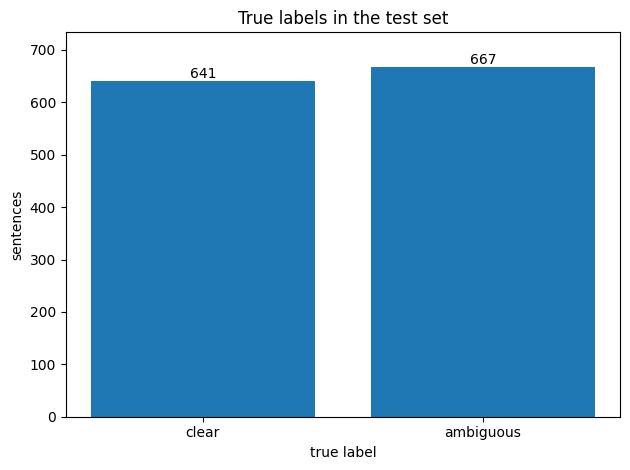

In [9]:
counts = df["true_label"].value_counts().sort_index()
counts.index = ["clear", "ambiguous"]

fig, ax = plt.subplots()
bars = ax.bar(counts.index, counts.values)
ax.bar_label(bars)
ax.set(title="True labels in the test set", xlabel="true label", ylabel="sentences",
       ylim=(0, counts.max() * 1.1))
plt.tight_layout()
plt.show()

### 2. Model confidence: right vs. wrong predictions
**Question:** How sure is the model when it is right, and when it is wrong?

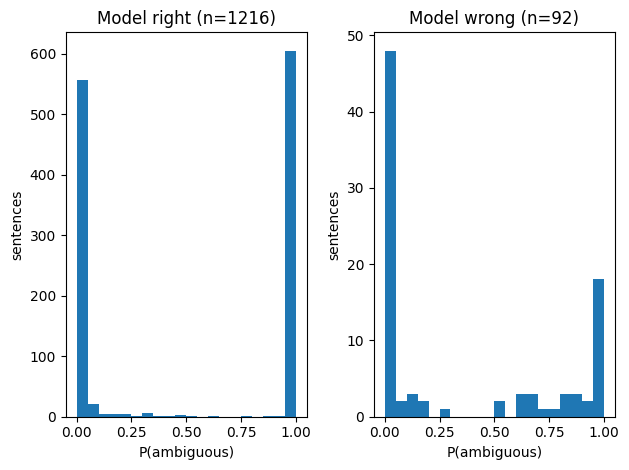

In [10]:
df["wrong"] = df["true_label"] != df["predicted_label"]

fig, axes = plt.subplots(1, 2, sharex=True)
for ax, wrong, name in zip(axes, [False, True], ["right", "wrong"]):
    part = df[df["wrong"] == wrong]
    ax.hist(part["probability_ambiguous"], bins=20, range=(0, 1))
    ax.set(title=f"Model {name} (n={len(part)})", xlabel="P(ambiguous)", ylabel="sentences")
plt.tight_layout()
plt.show()

**Finding:** The model is almost always very sure of its answer: most predictions are close to 0 or 1.

### 3. Sentences with and without modal words
**Question:** Does the model behave differently when a sentence contains a modal word?

               sentences  wrong  error_rate
without modal        937     90       0.096
with modal           371      2       0.005


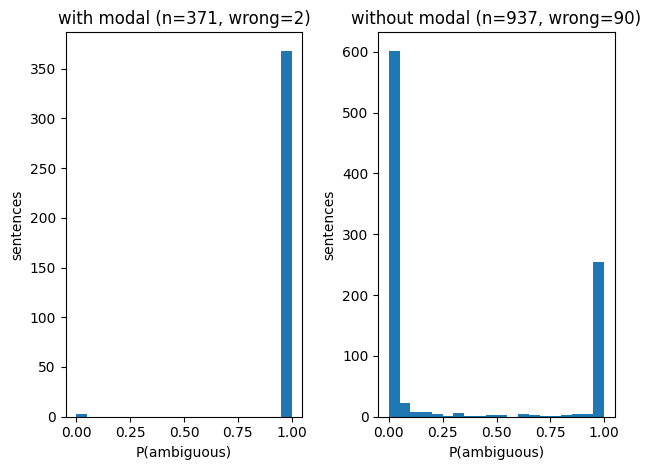

In [11]:
df["has_modal"] = df["requirement_text"].str.lower().str.contains(r"\b(?:should|may|might|could|can|would)\b")

summary = df.groupby("has_modal").agg(sentences=("wrong", "size"), wrong=("wrong", "sum"))
summary["error_rate"] = (summary["wrong"] / summary["sentences"]).round(3)
summary.index = ["without modal", "with modal"]
print(summary)

fig, axes = plt.subplots(1, 2, sharex=True)
for ax, modal, name in zip(axes, [True, False], ["with modal", "without modal"]):
    part = df[df["has_modal"] == modal]
    ax.hist(part["probability_ambiguous"], bins=20, range=(0, 1))
    ax.set(title=f"{name} (n={len(part)}, wrong={part['wrong'].sum()})",
           xlabel="P(ambiguous)", ylabel="sentences")
plt.tight_layout()
plt.show()

**Finding:** With a modal word, the model is almost never wrong. Without a modal word, the error rate is 9.6% (90 of 937), 90 of the 92 mistakes happen here. 370 of the 371 modal sentences are labeled ambiguous, so the modal word decides the label.

### 4. Missed ambiguous sentences by reason type
**Question:** Which kinds of ambiguity does the model miss most often?

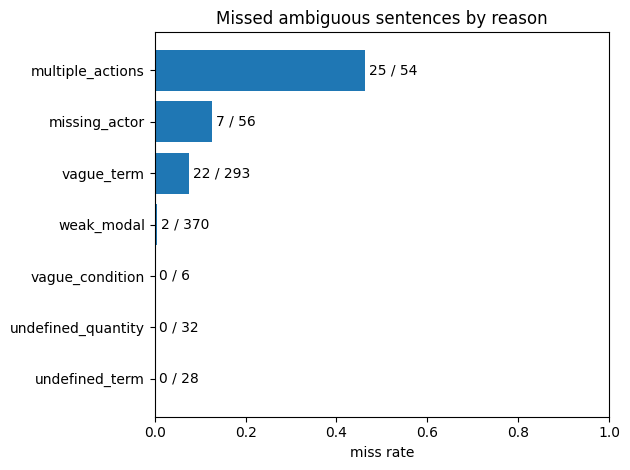

In [12]:
amb = df[df["true_label"] == 1].copy()
amb["reason"] = amb["reasons"].str.split(",")
amb = amb.explode("reason")

by_reason = amb.groupby("reason").agg(sentences=("wrong", "size"), missed=("wrong", "sum"))
by_reason["miss_rate"] = by_reason["missed"] / by_reason["sentences"]
by_reason = by_reason.sort_values("miss_rate")

fig, ax = plt.subplots()
bars = ax.barh(by_reason.index, by_reason["miss_rate"])
ax.bar_label(bars, labels=[f"{m} / {s}" for m, s in zip(by_reason["missed"], by_reason["sentences"])], padding=3)
ax.set(title="Missed ambiguous sentences by reason", xlabel="miss rate", xlim=(0, 1))
plt.tight_layout()
plt.show()

**Finding:** Sentences annotated with *multiple_actions* are missed more often than any other type: 25 of 54. The types with no misses (*undefined_quantity*, *undefined_term*, *vague_condition*) are small groups, so not reliable.

### 5. Error rate by sentence length
**Question:** Does the model make more mistakes on longer sentences?

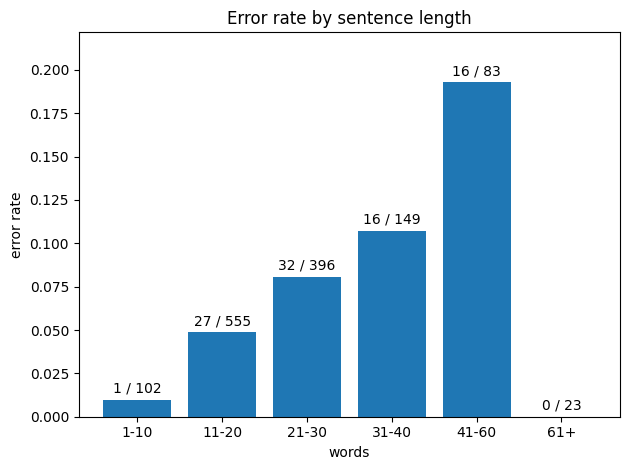

In [13]:
df["words"] = df["requirement_text"].str.split().str.len()
df["length"] = pd.cut(df["words"], bins=[0, 10, 20, 30, 40, 60, df["words"].max()],
                      labels=["1-10", "11-20", "21-30", "31-40", "41-60", "61+"])

by_length = df.groupby("length", observed=True).agg(sentences=("wrong", "size"), wrong=("wrong", "sum"))
by_length["error_rate"] = by_length["wrong"] / by_length["sentences"]

fig, ax = plt.subplots()
bars = ax.bar(by_length.index, by_length["error_rate"])
ax.bar_label(bars, labels=[f"{w} / {s}" for w, s in zip(by_length["wrong"], by_length["sentences"])], padding=3)
ax.set(title="Error rate by sentence length", xlabel="words", ylabel="error rate",
       ylim=(0, by_length["error_rate"].max() * 1.15))
plt.tight_layout()
plt.show()

**Finding:** The error rate rises with sentence length. The longest group (61+ words) has no mistakes, but with only 23 sentences this is not reliable.